[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/crunchdao/quickstarters/blob/master/competitions/causality-discovery/supervised_baseline/supervised_baseline.ipynb)

## Preliminary step

In [1]:
"""
This is a basic example of what you need to do to enter the crunch.
The code will not have access to the internet (or any socket related operation).
"""

import functools
import os
import typing

import joblib
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, ttest_rel
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
import pickle

/home/endrem/prosjekt/causalDiscovery/causalEnv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def graph_nodes_representation(graph, nodelist):
    """
    Create an alternative representation of a graph which is hashable
    and equivalent graphs have the same hash.

    Python cannot PROPERLY use nx.Graph/DiGraph as key for
    dictionaries, because two equivalent graphs with just different
    order of the nodes would result in different keys. This is
    undesirable here.

    So here we transform the graph into an equivalent form that is
    based on a specific nodelist and that is hashable. In this way,
    two equivalent graphs, once transformed, will result in identical
    keys.

    So we use the following trick: extract the adjacency matrix
    (with nodes in a fixed order) and then make a hashable thing out
    of it, through tuple(array.flatten()):
    """

    # This get the adjacency matrix with nodes in a given order, as
    # numpy array (which is not hashable):
    adjacency_matrix = nx.adjacency_matrix(graph, nodelist=nodelist).todense()

    # This transforms the numpy array into a hashable object:
    hashable = tuple(adjacency_matrix.flatten())

    return hashable

In [3]:
def create_graph_label():
    """
    Create a dictionary from graphs to labels, in two formats.
    """
    graph_label = {
        nx.DiGraph([("X", "Y"), ("v", "X"), ("v", "Y")]): "Confounder",
        nx.DiGraph([("X", "Y"), ("X", "v"), ("Y", "v")]): "Collider",
        nx.DiGraph([("X", "Y"), ("X", "v"), ("v", "Y")]): "Mediator",
        nx.DiGraph([("X", "Y"), ("v", "X")]):             "Cause of X",
        nx.DiGraph([("X", "Y"), ("v", "Y")]):             "Cause of Y",
        nx.DiGraph([("X", "Y"), ("X", "v")]):             "Consequence of X",
        nx.DiGraph([("X", "Y"), ("Y", "v")]):             "Consequence of Y",
        nx.DiGraph({"X": ["Y"], "v": []}):                "Independent",
    }

    nodelist = ["v", "X", "Y"]

    # This is an equivalent alternative to graph_label but in a form
    # for which two equivalent graphs have the same key:
    adjacency_label = {
        graph_nodes_representation(graph, nodelist): label
        for graph, label in graph_label.items()
    }

    return graph_label, adjacency_label

In [4]:
def get_labels(adjacency_matrix, adjacency_label):
    """
    Transform an adjacency_matrix (as pd.DataFrame) into a dictionary of variable:label
    """

    result = {}
    for variable in adjacency_matrix.columns.drop(["X", "Y"]):
        submatrix = adjacency_matrix.loc[[variable, "X", "Y"], [variable, "X", "Y"]]  # this is not hashable
        key = tuple(submatrix.values.flatten())  # this is hashable and a compatible with adjacency_label

        result[variable] = adjacency_label[key]

    return result

Example 1: manually creating the adjacency matrix.

In [5]:
graph_label, adjacency_label = create_graph_label()

Example 2: loading an adjacency matrix from the training set.

In [6]:
X_train = pd.read_pickle('./X_train.pkl')
y_train = pd.read_pickle('./y_train.pkl')
X_test = pd.read_pickle('./X_test.pkl')

with open('X_y_group_train.pkl', 'rb') as f:
    X_y_group_train_loaded = pickle.load(f)

In [7]:
def pearson_correlation(dataset, spearman=False):
    """
    Given a dataset, we compute the correlation-based features for each
    varibale, which are the correlation between that variable with X and Y,
    as well as summary statistics (max, min, mean, std) of all pairs
    of correlations.
    """

    variables = dataset.columns.drop(["X", "Y"])

    df = []
    for variable in variables:
        if spearman==False:
            the_method = 'pearson'
        else:
            the_method = 'spearman'

        tmp = dataset.corr(method=the_method).drop([variable], axis="columns").loc[variable].abs()

        corr_v_x = 0
        corr_v_y = 0
        max_corr = 0
        min_corr = 0
        mean_corr = 0
        std_corr = 0
        std25_corr = 0
        std75_corr = 0
        median_corr = 0
        corr_x_y = 0
        if not tmp.isna().all():
            corr_v_x = dataset[[variable, "X"]].corr(the_method).loc[variable, "X"]
            corr_v_y = dataset[[variable, "Y"]].corr(the_method).loc[variable, "Y"]
            max_corr = tmp.max()
            min_corr = tmp.min()
            mean_corr = tmp.mean()
            std_corr = tmp.std()
            std25_corr = np.percentile(tmp.values, 25)
            std75_corr = np.percentile(tmp.values, 75)
            median_corr = tmp.median()
            corr_x_y = dataset[["Y", "X"]].corr().loc["Y", "X"]

        df.append({
            "variable": variable,
            "corr(v,X)": corr_v_x,
            "corr(v,Y)": corr_v_y,
            "max(corr(v, others))": max_corr,
            "min(corr(v, others))": min_corr,
            "mean(corr(v, others))": mean_corr,
            "std(corr(v, others))": std_corr,
            "std25(corr(v, others))": std25_corr,
            "std75(corr(v, others))": std75_corr,
            "median(corr(v, others))": median_corr,
            "corr(X,Y)": corr_x_y
        })

    df = pd.DataFrame(df)
    df["dataset"] = dataset.name

    df["corr(X,Y)"] = dataset[["X", "Y"]].corr(method=the_method).loc["X", "Y"]

    # pearsonr is NaN when the variance is 0, so we fill with 0
    df.fillna(0, inplace=True)

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df

In [8]:
def spearman_correlation(dataset):
    return pearson_correlation(dataset, spearman=True)

In [9]:
import pandas as pd
import numpy as np
from scipy.stats import energy_distance

def energy_distance_features(dataset):
    """
    Given a dataset, we compute the energy distance-based features for each
    variable, which are the energy distance between that variable with X and Y,
    as well as summary statistics (max, min, mean, std) of all pairs
    of energy distances.
    """

    variables = dataset.columns.drop(["X", "Y"])

    df = []
    for variable in variables:
        tmp = dataset.apply(lambda col: energy_distance(dataset[variable], col)).drop([variable, "X", "Y"])

        energy_dist_v_x = 0
        energy_dist_v_y = 0
        max_energy_dist = 0
        min_energy_dist = 0
        mean_energy_dist = 0
        std_energy_dist = 0
        std25_energy_dist = 0
        std75_energy_dist = 0
        median_energy_dist = 0
        energy_dist_x_y = 0
        if not tmp.isna().all():
            energy_dist_v_x = energy_distance(dataset[variable], dataset["X"])
            energy_dist_v_y = energy_distance(dataset[variable], dataset["Y"])
            max_energy_dist = tmp.max()
            min_energy_dist = tmp.min()
            mean_energy_dist = tmp.mean()
            std_energy_dist = tmp.std()
            std25_energy_dist = np.percentile(tmp.values, 25)
            std75_energy_dist = np.percentile(tmp.values, 75)
            median_energy_dist = tmp.median()
            energy_dist_x_y = energy_distance(dataset["X"], dataset["Y"])

        df.append({
            "variable": variable,
            "energy_dist(v,X)": energy_dist_v_x,
            "energy_dist(v,Y)": energy_dist_v_y,
            "max(energy_dist(v, others))": max_energy_dist,
            "min(energy_dist(v, others))": min_energy_dist,
            "mean(energy_dist(v, others))": mean_energy_dist,
            "std(energy_dist(v, others))": std_energy_dist,
            "std25(energy_dist(v, others))": std25_energy_dist,
            "std75(energy_dist(v, others))": std75_energy_dist,
            "median(energy_dist(v, others))": median_energy_dist,
            "energy_dist(X,Y)": energy_dist_x_y
        })

    df = pd.DataFrame(df)
    df["dataset"] = dataset.name

    df["energy_dist(X,Y)"] = energy_distance(dataset["X"], dataset["Y"])

    # Fill NaN values with 0
    df.fillna(0, inplace=True)

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df


In [ ]:
if False:
    df = []
    for name, dataset in tqdm(X_train.items()):
        dataset = X_train[name]
        dataset.name = name

        df_dataset = energy_distance_features(dataset) #spearman_correlation(dataset) #pearson_correlation_with_rolling_multi_labeled(dataset)
        
        df_dataset["dataset"] = name
        df.append(df_dataset)

    df = pd.concat(df, axis="index").reset_index(drop=True)
    print("done")

100%|██████████| 23500/23500 [11:09<00:00, 35.09it/s]


done


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def pearson_correlation_with_rolling_multi_labeled(dataset, window_sizes=[300, 600, 900]):
    """
    Compute rolling correlation statistics for each variable with respect to X and Y
    over rolling windows of sizes 300, 600, and 900.
    Each statistic is labeled with _<window_size>.
    """
    variables = dataset.columns.drop(["X", "Y"])
    df = []

    for variable in variables:
        
        rolling_stats = {}
        rolling_stats["variable"] = variable

        for window_size in window_sizes:
            #plt.plot(rolling_corr_X[298:])
            #plt.show()

            corr_v_x_300_3 = 0
            corr_v_x_300_9 = 0
            corr_v_y_300_3 = 0
            corr_v_y_300_9 = 0
            max_corr_300 = 0
            min_corr_300 = 0
            mean_corr_300 = 0
            std_corr_300 = 0
            std25_corr_300 = 0
            std75_corr_300 = 0
            median_corr_300 = 0
            corr_x_y_300 = 0

            #tmp = dataset.rolling(window=window_size).corr().drop([variable], axis="columns").loc[999].loc[variable].abs()
            tmp = dataset.iloc[-window_size:].corr().drop([variable], axis="columns").loc[variable].abs()

            if not tmp.isna().all():
                corr_v_x_300_3 = dataset[[variable, "X"]].iloc[:window_size].corr().loc[variable]['X']
                corr_v_x_300_9 = dataset[[variable, "X"]].iloc[-window_size:].corr().loc[variable]['X']
                corr_v_y_300_3 = dataset[[variable, "Y"]].iloc[:window_size].corr().loc[variable]['Y']
                corr_v_y_300_9 = dataset[[variable, "Y"]].iloc[-window_size:].corr().loc[variable]['Y']
                max_corr_300 = tmp.max()
                min_corr_300 = tmp.min()
                mean_corr_300 = tmp.mean()
                std_corr_300 = tmp.std()
                std25_corr_300 = np.percentile(tmp.values, 25)
                std75_corr_300 = np.percentile(tmp.values, 75)
                median_corr_300 = tmp.median()
                corr_x_y_300 = dataset[["Y", "X"]].iloc[-window_size:].corr().loc['Y']['X']

            rolling_stats[f"corr(v,X)_{window_size}_3"] = corr_v_x_300_3
            rolling_stats[f"corr(v,X)_{window_size}_9"] = corr_v_x_300_9
            rolling_stats[f"corr(v,Y)_{window_size}_3"] = corr_v_y_300_3
            rolling_stats[f"corr(v,Y)_{window_size}_9"] = corr_v_y_300_9
            rolling_stats[f"max(corr(v, others))_{window_size}"] = max_corr_300
            rolling_stats[f"min(corr(v, others))_{window_size}"] = min_corr_300
            rolling_stats[f"mean(corr(v, others))_{window_size}"] = mean_corr_300
            rolling_stats[f"std(corr(v, others))_{window_size}"] = std_corr_300
            rolling_stats[f"25th(corr(v, others))_{window_size}"] = std25_corr_300
            rolling_stats[f"75th(corr(v, others))_{window_size}"] = std75_corr_300
            rolling_stats[f"median(corr(v, others))_{window_size}"] = median_corr_300
            rolling_stats[f"corr(X,Y)_{window_size}"] = corr_x_y_300

        df.append(rolling_stats)

    # Convert results into a DataFrame
    result_df = pd.DataFrame(df)

    return result_df


In [31]:
# Example dataset
data = pd.DataFrame({
    "X": np.random.rand(1000),
    "Y": np.random.rand(1000),
    "A": np.random.rand(1000),
    "B": np.random.rand(1000),
    "C": np.random.rand(1000),
})

# Add dataset name (optional for this implementation)
data.name = "Example Dataset"

# Compute correlations with rolling window size of 300
summary_df = partial_correlation(data)

display(summary_df)

summary_df = partial_correlation_rank(data) 

display(summary_df)

,dataset,variable,"partial_corr(v,X|Y)","partial_corr(v,Y|X)","partial_corr(X,Y|v)"
0,Example Dataset,A,0.020482,-0.016956,0.009189
1,Example Dataset,B,0.003756,-0.020486,0.008920
2,Example Dataset,C,-0.012618,-0.010642,0.008709


,dataset,variable,"partial_corr_rank(v,X|Y)","partial_corr_rank(v,Y|X)","partial_corr_rank(X,Y|v)"
0,Example Dataset,A,0.019448,-0.018040,0.008397
1,Example Dataset,B,0.003225,-0.022366,0.008121
2,Example Dataset,C,-0.011947,-0.012028,0.007479


In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

def partial_correlation(dataset):
    """
    Computes partial correlation features for each variable in the dataset.
    Features:
    - partial_corr(v, X | Y)
    - partial_corr(v, Y | X)
    - partial_corr(X, Y | v)
    """
    variables = dataset.columns.drop(["X", "Y"])
    df = []

    for variable in variables:
        # Initialize partial correlations
        pcorr_v_X_given_Y = np.nan
        pcorr_v_Y_given_X = np.nan
        pcorr_X_Y_given_v = np.nan

        # Check for zero variance in variables
        if (dataset[variable].std() == 0 or
            dataset["X"].std() == 0 or
            dataset["Y"].std() == 0):
            print(f"Zero variance detected in variable: {variable}")
            # Skip this variable or assign correlations as NaN
            pass
        else:
            # partial_corr(v, X | Y)
            # Regress v on Y
            model_v_Y = LinearRegression().fit(dataset[["Y"]], dataset[variable])
            residuals_v_Y = dataset[variable] - model_v_Y.predict(dataset[["Y"]])

            # Regress X on Y
            model_X_Y = LinearRegression().fit(dataset[["Y"]], dataset["X"])
            residuals_X_Y = dataset["X"] - model_X_Y.predict(dataset[["Y"]])

            # Check for zero variance in residuals
            if residuals_v_Y.std() == 0 or residuals_X_Y.std() == 0:
                print(f"Zero variance in residuals for variable: {variable}")
                pcorr_v_X_given_Y = 0  # or np.nan
            else:
                pcorr_v_X_given_Y = np.corrcoef(residuals_v_Y, residuals_X_Y)[0, 1]

            # partial_corr(v, Y | X)
            # Regress v on X
            model_v_X = LinearRegression().fit(dataset[["X"]], dataset[variable])
            residuals_v_X = dataset[variable] - model_v_X.predict(dataset[["X"]])

            # Regress Y on X
            model_Y_X = LinearRegression().fit(dataset[["X"]], dataset["Y"])
            residuals_Y_X = dataset["Y"] - model_Y_X.predict(dataset[["X"]])

            # Check for zero variance in residuals
            if residuals_v_X.std() == 0 or residuals_Y_X.std() == 0:
                print(f"Zero variance in residuals for variable: {variable}")
                pcorr_v_Y_given_X = 0  # or np.nan
            else:
                pcorr_v_Y_given_X = np.corrcoef(residuals_v_X, residuals_Y_X)[0, 1]

            # partial_corr(X, Y | v)
            # Regress X on v
            model_X_v = LinearRegression().fit(dataset[[variable]], dataset["X"])
            residuals_X_v = dataset["X"] - model_X_v.predict(dataset[[variable]])

            # Regress Y on v
            model_Y_v = LinearRegression().fit(dataset[[variable]], dataset["Y"])
            residuals_Y_v = dataset["Y"] - model_Y_v.predict(dataset[[variable]])

            # Check for zero variance in residuals
            if residuals_X_v.std() == 0 or residuals_Y_v.std() == 0:
                print(f"Zero variance in residuals for variable: {variable}")
                pcorr_X_Y_given_v = 0  # or np.nan
            else:
                pcorr_X_Y_given_v = np.corrcoef(residuals_X_v, residuals_Y_v)[0, 1]

        df.append({
            "variable": variable,
            "partial_corr(v,X|Y)": pcorr_v_X_given_Y,
            "partial_corr(v,Y|X)": pcorr_v_Y_given_X,
            "partial_corr(X,Y|v)": pcorr_X_Y_given_v
        })

    df = pd.DataFrame(df)
    df["dataset"] = getattr(dataset, "name", None)

    # Reorder columns
    df = df[["dataset", "variable", "partial_corr(v,X|Y)", "partial_corr(v,Y|X)", "partial_corr(X,Y|v)"]]

    # Fill NaNs with 0
    df.fillna(0, inplace=True)

    return df

In [32]:
from sklearn.linear_model import LinearRegression
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

def partial_correlation_rank(dataset):
    """
    Computes partial correlation features using Spearman's rank correlation.
    Features:
    - partial_corr_rank(v, X | Y)
    - partial_corr_rank(v, Y | X)
    - partial_corr_rank(X, Y | v)
    """
    variables = dataset.columns.drop(["X", "Y"])
    df = []

    # Rank transform the data
    ranked_data = dataset.rank()

    for variable in variables:
        # Initialize partial correlations to zero
        pcorr_v_X_given_Y = 0
        pcorr_v_Y_given_X = 0
        pcorr_X_Y_given_v = 0

        # Check for zero variance in variables
        if (ranked_data[variable].std() == 0 or
            ranked_data["X"].std() == 0 or
            ranked_data["Y"].std() == 0):
            # Assign partial correlations as zero
            pass
        else:
            # partial_corr_rank(v, X | Y)
            pcorr_v_X_given_Y = partial_corr_spearman(ranked_data[variable], ranked_data["X"], ranked_data["Y"])

            # partial_corr_rank(v, Y | X)
            pcorr_v_Y_given_X = partial_corr_spearman(ranked_data[variable], ranked_data["Y"], ranked_data["X"])

            # partial_corr_rank(X, Y | v)
            pcorr_X_Y_given_v = partial_corr_spearman(ranked_data["X"], ranked_data["Y"], ranked_data[variable])

        # Append results with features assigned as zero where necessary
        df.append({
            "variable": variable,
            "partial_corr_rank(v,X|Y)": pcorr_v_X_given_Y,
            "partial_corr_rank(v,Y|X)": pcorr_v_Y_given_X,
            "partial_corr_rank(X,Y|v)": pcorr_X_Y_given_v
        })

    df = pd.DataFrame(df)
    df["dataset"] = getattr(dataset, "name", None)
    df = df[["dataset", "variable",
             "partial_corr_rank(v,X|Y)", "partial_corr_rank(v,Y|X)", "partial_corr_rank(X,Y|v)"]]
    df.fillna(0, inplace=True)

    return df

def partial_corr_spearman(x, y, control):
    """
    Computes the partial Spearman correlation coefficient between x and y controlling for control.
    Returns 0 if any variable has zero variance or residuals have zero variance.
    """
    # Check for zero variance in control variable
    if control.std() == 0:
        return 0  # Cannot regress on control with zero variance

    # Regress x on control
    if x.std() == 0:
        residuals_x = x - x.mean()
    else:
        model_x = LinearRegression()
        model_x.fit(control.values.reshape(-1, 1), x)
        residuals_x = x - model_x.predict(control.values.reshape(-1, 1))

    # Regress y on control
    if y.std() == 0:
        residuals_y = y - y.mean()
    else:
        model_y = LinearRegression()
        model_y.fit(control.values.reshape(-1, 1), y)
        residuals_y = y - model_y.predict(control.values.reshape(-1, 1))

    # Check for zero variance in residuals
    if residuals_x.std() == 0 or residuals_y.std() == 0:
        return 0  # Cannot compute correlation with zero variance residuals

    # Compute Spearman correlation between residuals
    corr_coef, _ = spearmanr(residuals_x, residuals_y)

    # Assign zero if correlation is NaN
    if np.isnan(corr_coef):
        corr_coef = 0

    return corr_coef

In [33]:
def ttest(dataset, pvalue_threshold=0.05):
    """
    Given a dataset, this function computes the t-test between the
    values each variable v and X, Y. The t value and the result of the
    t-test with a given pvalue_threshold, are used to create features
    to describe/embed v, as well as the t-test result between the
    values of X and Y.
    """

    variables = dataset.columns.drop(["X", "Y"])

    df = []
    for variable in variables:
        ttest_vX = ttest_rel(dataset[variable], dataset["X"])
        ttest_vY = ttest_rel(dataset[variable], dataset["Y"])

        df.append({
            "variable": variable,
            "ttest(v,X)": ttest_vX.statistic,
            f"pvalue(ttest(v,X))<={pvalue_threshold}": (ttest_vX.pvalue <= pvalue_threshold).astype(float),
            "ttest(v,Y)": ttest_vY.statistic,
            f"pvalue(ttest(v,Y))<={pvalue_threshold}": (ttest_vY.pvalue <= pvalue_threshold).astype(float),
        })

    df = pd.DataFrame(df)
    df["dataset"] = dataset.name

    ttest_XY = ttest_rel(dataset["X"], dataset["Y"])
    df["ttest(X,Y)"] = ttest_XY.statistic
    df[f"pvalue(ttest(X,Y))<={pvalue_threshold}"] = (ttest_XY.pvalue <= pvalue_threshold).astype(float)

    # some the ttest returns NaN when the variance is 0, so we fill with 0:
    df.fillna(0, inplace=True)

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df

In [12]:
def mutual_information(dataset):
    """
    Given a dataset, we compute the mutual-information-based features
    for each varibale, which are the correlation between that variable
    X and Y, as well as summary statistics (max, min, mean, std) of
    all pairs of correlations.
    """

    variables = dataset.columns.drop(["X", "Y"])

    df = []
    for variable in variables:
        tmp = mutual_info_regression(dataset.drop(columns=[variable]), dataset[variable])

        df.append({
            "variable": variable,
            "MI(v,X)": mutual_info_regression(dataset[[variable]], dataset["X"], discrete_features=False)[0],
            "MI(v,Y)": mutual_info_regression(dataset[[variable]], dataset["Y"], discrete_features=False)[0],
            "max(MI(v, others))": tmp.max(),
            "min(MI(v, others))": tmp.min(),
            "mean(MI(v, others))": tmp.mean(),
            "std(MI(v, others))": tmp.std(),
        })

    df = pd.DataFrame(df)
    df["dataset"] = dataset.name

    df["MI(X,Y)"] = mutual_info_regression(dataset[["X"]], dataset["Y"], discrete_features=False)[0]

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df

In [13]:
def label(adjacency_matrix):
    """
    Given a graph as adjacency_matrix, create the class labels of each variable.
    """

    adjacency_graph, adjacency_label = create_graph_label()
    labels = get_labels(adjacency_matrix, adjacency_label)
    variables = adjacency_matrix.columns.drop(["X", "Y"])

    df = pd.DataFrame({
        "variable": variables,
        "label": [labels[variable] for variable in variables],
    })
    df["dataset"] = adjacency_matrix.name

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df

In [14]:
def create_some_columns(names_datasets, function):
    """
    Apply an embedding function to a list of datasets.
    """

    df = []
    for name, dataset in tqdm(names_datasets.items()):
        dataset = names_datasets[name]
        dataset.name = name

        try:
            df_dataset = function(dataset)
        except ValueError as e:
            print(name, e)
            raise NotImplementedError

        df_dataset["dataset"] = name
        df.append(df_dataset)

    df = pd.concat(df, axis="index").reset_index(drop=True)
    return df

In [15]:
def create_some_columns_parallel(names_datasets, function, n_jobs=-1):
    """
    Apply an embedding function to a list of datasets.

    Parallel version.
    """

    def f(name, dataset, function):
        dataset.name = name
        df_dataset = function(dataset)
        df_dataset["dataset"] = name
        return df_dataset

    df = joblib.Parallel(n_jobs=n_jobs)(
        joblib.delayed(f)(name, dataset, function)
        for name, dataset in tqdm(names_datasets.items())
    )

    df = pd.concat(df, axis="index").reset_index(drop=True)
    return df

In [16]:
def create_all_columns(functions_names_datasets, n_jobs=-1):
    """
    given a dictionary of {function1:names, function2:names,...} apply
    the desired functions to the list of datasets and merge all of them
    in a single X_y_group dataframe.
    """

    columns = []
    for function, names_datasets in functions_names_datasets.items():
        print(f"set: {function.__name__}")

        if n_jobs != 1:
            feature_set = create_some_columns_parallel(names_datasets, function, n_jobs=n_jobs)
        else:
            feature_set = create_some_columns(names_datasets, function)

        columns.append(feature_set)

    # Merge all feature sets into a single dataframe:
    columns = functools.reduce(
        lambda left, right: pd.merge(left, right, on=["dataset", "variable"]),
        columns,
    )

    return columns

We now compute `(X_train, y_train)` from all training datasets and graphs, and store it in a single dataframe `X_y_group_train`, which also contains the name of the dataset to which each variable belongs.

In Google Colab, the cell below takes about half an hour to compute. We keep `n_jobs=1` to avoid excessive memory usage.

In [21]:
names_datasets_train = X_train
names_graphs_train = y_train

print(f"Creating X_y_group_train from {len(names_datasets_train)} datasets and graphs")
X_y_group_train = create_all_columns(
    {
        energy_distance_features: names_datasets_train,
        pearson_correlation: names_datasets_train,
        spearman_correlation: names_datasets_train,
        pearson_correlation_with_rolling_multi_labeled: names_datasets_train,
        ttest: names_datasets_train,
        mutual_information: names_datasets_train,  # uncomment this line to add features but at high computational cost
        label: names_graphs_train,
    },
    n_jobs=-1,
)

Creating X_y_group_train from 23500 datasets and graphs
set: energy_distance_features


100%|██████████| 23500/23500 [04:29<00:00, 87.09it/s] 


set: pearson_correlation


100%|██████████| 23500/23500 [02:16<00:00, 172.49it/s]


set: spearman_correlation


100%|██████████| 23500/23500 [03:23<00:00, 115.67it/s]


... (4 outputs left out)

set: mutual_information


100%|██████████| 23500/23500 [39:58<00:00,  9.80it/s]


set: label


100%|██████████| 23500/23500 [00:51<00:00, 452.78it/s]


In [39]:
create_feature_file = True
if create_feature_file:
    with open('X_y_group_train.pkl', 'wb') as f:
        pickle.dump(X_y_group_train, f)

    X_y_group_train

In [22]:
print("Adding numeric labels y")
le = LabelEncoder()
X_y_group_train["y"] = le.fit_transform(X_y_group_train["label"])
# reordering columns:
X_y_group_train = X_y_group_train[["dataset", "variable"] + X_y_group_train.columns.drop(["dataset", "variable", "label", "y"]).tolist() + ["label", "y"]]
#display(X_y_group_train)

print("Extracting X_train, y_train, and group")
X_train_feat = X_y_group_train.drop(["variable", "dataset", "label", "y"], axis="columns")
y_train_feat = X_y_group_train["y"]
group_train = X_y_group_train["dataset"]
print(X_train_feat.shape)

Adding numeric labels y
Extracting X_train, y_train, and group
(142910, 79)


In [ ]:
#GAE
# A gradient-based algorithm using graph autoencoder to model non-linear causal relationships

#weighted_random_dag = DAG.erdos_renyi(n_nodes=10, n_edges=20, weight_range=(0.5, 2.0), seed=1)
#dataset = IIDSimulation(W=weighted_random_dag, n=2000, method='linear', sem_type='gauss')
#true_dag, X = dataset.B, dataset.X

if False:
    A = names_graphs_train['00016']
    print(X_train)
    X = X_train['00016']
    print("y_true:", A)
    print("X:", X.head())

    ga = GAE(input_dim=10)
    ga.learn(X)

    # plot est_dag and true_dag
    GraphDAG(ga.causal_matrix, true_dag)

    # calculate accuracy
    met = MetricsDAG(ga.causal_matrix, true_dag)
    print(met.metrics)

In [ ]:
X_train_feat['corr(v,X)_600_3']

KeyError: 'X'

In [23]:
#shape 16
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=11,
    n_jobs=-1,
    class_weight="balanced"
)
display(model)

print("X_train shape:", X_train_feat.shape)
print("X_train data types:", X_train_feat.dtypes)
print("y_train shape:", y_train_feat.shape)
print("y_train data type:", y_train_feat.dtype)
print("group_train shape:", group_train.shape)
print("group_train data type:", group_train.dtype)

cv = GroupKFold(n_splits=4)
results = cross_val_score(
    model,
    X_train_feat,
    y_train_feat,
    groups=group_train,
    cv=cv,
    verbose=True,
    scoring="balanced_accuracy"
)

print(f"multiclass balanced accuracy: mean={results.mean()}")

RandomForestClassifier(class_weight='balanced', max_depth=11, n_estimators=200,
                       n_jobs=-1)

X_train shape: (142910, 79)
X_train data types: energy_dist(v,X)                float64
energy_dist(v,Y)                float64
max(energy_dist(v, others))     float64
min(energy_dist(v, others))     float64
mean(energy_dist(v, others))    float64
                                 ...   
max(MI(v, others))              float64
min(MI(v, others))              float64
mean(MI(v, others))             float64
std(MI(v, others))              float64
MI(X,Y)                         float64
Length: 79, dtype: object
y_train shape: (142910,)
y_train data type: int64
group_train shape: (142910,)
group_train data type: object
multiclass balanced accuracy: mean=0.38552181377921824


In [22]:
print(X_train_feat.shape)
X_train_feat.columns

(142910, 72)


Index(['energy_dist(v,X)', 'energy_dist(v,Y)', 'max(energy_dist(v, others))',
       'min(energy_dist(v, others))', 'mean(energy_dist(v, others))',
       'std(energy_dist(v, others))', 'std25(energy_dist(v, others))',
       'std75(energy_dist(v, others))', 'median(energy_dist(v, others))',
       'energy_dist(X,Y)', 'corr(v,X)_x', 'corr(v,Y)_x',
       'max(corr(v, others))_x', 'min(corr(v, others))_x',
       'mean(corr(v, others))_x', 'std(corr(v, others))_x',
       'std25(corr(v, others))_x', 'std75(corr(v, others))_x',
       'median(corr(v, others))_x', 'corr(X,Y)_x', 'corr(v,X)_y',
       'corr(v,Y)_y', 'max(corr(v, others))_y', 'min(corr(v, others))_y',
       'mean(corr(v, others))_y', 'std(corr(v, others))_y',
       'std25(corr(v, others))_y', 'std75(corr(v, others))_y',
       'median(corr(v, others))_y', 'corr(X,Y)_y', 'corr(v,X)_300_3',
       'corr(v,X)_300_9', 'corr(v,Y)_300_3', 'corr(v,Y)_300_9',
       'max(corr(v, others))_300', 'min(corr(v, others))_300',
       '

In [24]:
import lightgbm as lgb
from sklearn.model_selection import GroupKFold, cross_val_score
import re

# Clean feature names
X_train_feat.columns = [col.replace(' ', '_').replace('"', '').replace("'", '') for col in X_train_feat.columns]
X_train_feat = X_train_feat.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '', x))

# Check for constant features
constant_features = [col for col in X_train_feat.columns if X_train_feat[col].nunique() == 1]
if constant_features:
    print(f"Constant features: {constant_features}")
    X_train_feat = X_train_feat.drop(columns=constant_features)

# Check for missing values
missing_values = X_train_feat.isnull().sum()
if missing_values.any():
    print(f"Missing values: {missing_values[missing_values > 0]}")
    X_train_feat = X_train_feat.fillna(0)  # Fill missing values with 0 or use an appropriate strategy



# Define the model
model = lgb.LGBMClassifier(
    n_estimators=200,
    max_depth=11,
    n_jobs=-1,
    class_weight="balanced",
    verbose=0,
    min_child_samples=20,  # Minimum number of data points in a leaf
    min_split_gain=0.01,   # Minimum gain to make a split
    learning_rate=0.1      # Learning rate
)
display(model)

# Print the shapes of the training data
print("X_train shape:", X_train_feat.shape)
print("y_train shape:", y_train_feat.shape)
print("group_train shape:", group_train.shape)

# Define the cross-validation strategy
cv = GroupKFold(n_splits=4)

# Perform cross-validation
results = cross_val_score(
    model,
    X_train_feat,
    y_train_feat,
    groups=group_train,
    cv=cv,
    verbose=True,
    scoring="balanced_accuracy"
)

# Print the mean balanced accuracy
print(f"Multiclass balanced accuracy: mean={results.mean()}")

Missing values: 25thcorrv_others_300    25
75thcorrv_others_300    25
25thcorrv_others_600    25
75thcorrv_others_600    25
25thcorrv_others_900    25
75thcorrv_others_900    25
dtype: int64


LGBMClassifier(class_weight='balanced', max_depth=11, min_split_gain=0.01,
               n_estimators=200, n_jobs=-1, verbose=0)

X_train shape: (142910, 79)
y_train shape: (142910,)
group_train shape: (142910,)
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Multiclass balanced accuracy: mean=0.40583165197637927


First dataset with columns 'X', 'Y', and '0' is: 00229
First dataset with columns 'X', 'Y', and '0' is: 00463
First dataset with columns 'X', 'Y', and '0' is: 00618


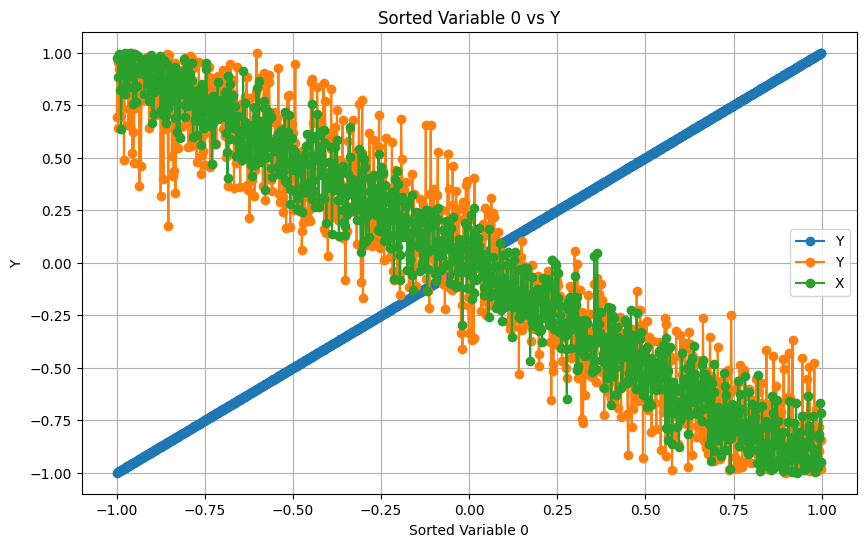

         0      X      Y
0   -0.999  0.973  0.693
1   -0.997  0.981  0.957
2   -0.995  0.885  0.641
3   -0.993  0.993  0.921
4   -0.991  0.821  0.953
..     ...    ...    ...
995  0.991 -0.833 -0.895
996  0.993 -0.817 -0.781
997  0.995 -0.667 -0.961
998  0.997 -0.947 -0.979
999  0.999 -0.715 -0.841

[1000 rows x 3 columns]
          0         X         Y
0  1.000000 -0.980416 -0.946663
X -0.980416  1.000000  0.961904
Y -0.946663  0.961904  1.000000


In [ ]:
x16 = X_train['00016']
y16 = y_train['00016']

count = 0
for name, dataset in X_train.items():
    # Check if the dataset has exactly three columns named 'X', 'Y', and '0'
    if set(dataset.columns) == {'X', 'Y', '0'}:
        print(f"First dataset with columns 'X', 'Y', and '0' is: {name}")
        x16 = dataset
        if count == 2:
            break
        count += 1

sorted_x16 = x16.sort_values(by='0').reset_index(drop=True)

plt.figure(figsize=(10, 6))
plt.plot(sorted_x16['0'], sorted_x16['0'], marker='o', label='Y')
plt.plot(sorted_x16['0'], sorted_x16['Y'], marker='o', label='Y')
plt.plot(sorted_x16['0'], sorted_x16['X'], marker='o', label='X')
plt.xlabel('Sorted Variable 0')
plt.ylabel('Y')
plt.title('Sorted Variable 0 vs Y')
plt.legend()
plt.grid(True)
plt.show()

# Print the sorted DataFrame
print(sorted_x16)

print(x16.corr())

## CrunchDAO Code Interface

[Submitting to the CrunchDAO platform requires 2 functions, `train` and `infer`.](https://docs.crunchdao.com/competitions/code-interface) Any line that is not in a function or is not an import will be commented when the notebook is processed.

The content of the function is the same as the example, but the train must save the model to be read in infer. This allows for more predictable behavior if the program is restarted without training.

In [ ]:
# Uncomment what you need!
def train(
    X_train: typing.Dict[str, pd.DataFrame],
    y_train: typing.Dict[str, pd.DataFrame],
    # number_of_features: int,
    model_directory_path: str,
    # id_column_name: str,
    # prediction_column_name: str,
    # has_gpu: bool,
) -> None:
    # 1) Create the variable embedding:
    X_y_group_train_pathname = "/tmp/X_y_group_train.parquet"
    try:
        print(f"Loading {X_y_group_train_pathname}")
        X_y_group_train = pd.read_parquet(X_y_group_train_pathname)
    except FileNotFoundError:
        print("Creating X_y_group_train")
        names_datasets_train = X_train
        names_graphs_train = y_train
        X_y_group_train = create_all_columns(
            {
                pearson_correlation: names_datasets_train,
                ttest: names_datasets_train,
                mutual_information: names_datasets_train,  # comment this line to greatly reduce computation
                label: names_graphs_train,
            },
            n_jobs=-1,
        )

        # 2) Massage X_y_group_train to prepare what is needed by the model:
        print("Adding numeric labels y") # sklearn wants numeric labels
        le = LabelEncoder()
        le.classes_ = np.array([
            'Cause of X', 'Consequence of X', 'Confounder', 'Collider',
            'Mediator', 'Independent', 'Cause of Y', 'Consequence of Y',
        ])
        X_y_group_train["y"] = le.transform(X_y_group_train["label"])

        # reordering columns:
        X_y_group_train = X_y_group_train[["dataset", "variable"] + X_y_group_train.columns.drop(["dataset", "variable", "label", "y"]).tolist() + ["label", "y"]]
        display(X_y_group_train)

        print("Saving X_y_group_train")
        os.makedirs(os.path.dirname(X_y_group_train_pathname), exist_ok=True)
        X_y_group_train.to_parquet(X_y_group_train_pathname)

    print("Extracting X_train, y_train, and group")
    X_train = X_y_group_train.drop(["variable", "dataset", "label", "y"], axis="columns")
    y_train = X_y_group_train["y"]
    group_train = X_y_group_train["dataset"]

    # Model:
    model = RandomForestClassifier(n_estimators=100, max_depth=11, n_jobs=-1, class_weight="balanced")
    model.fit(X_train, y_train)

    joblib.dump(
        model,
        os.path.join(model_directory_path, "model.joblib")
    )

In [ ]:
def create_submission(X_y_pred_test):
    """
    From the predicted test set, for each dataset, take predicted
    classes of all variables, create the adjacency matrix, then create
    the submission in the requested format.
    """

    submission = {}
    for name, prediction in tqdm(X_y_pred_test.groupby("dataset"), delay=10):
        variables_labels = prediction[["variable", "label_predicted"]].set_index("variable")
        variables = variables_labels.index.tolist()
        variables_all = ["X", "Y"] + variables

        adjacency_matrix = pd.DataFrame(index=variables_all, columns=variables_all)
        adjacency_matrix.index.name = "parent"
        adjacency_matrix[:] = 0
        adjacency_matrix.loc["X", "Y"] = 1

        for v in variables:
            l = variables_labels.loc[v].item()
            if l == "Cause of X":
                adjacency_matrix.loc[v, "X"] = 1
            elif l == "Cause of Y":
                adjacency_matrix.loc[v, "Y"] = 1
            elif l == "Consequence of X":
                adjacency_matrix.loc["X", v] = 1
            elif l == "Consequence of Y":
                adjacency_matrix.loc["Y", v] = 1
            elif l == "Confounder":
                adjacency_matrix.loc[v, "X"] = 1
                adjacency_matrix.loc[v, "Y"] = 1
            elif l == "Collider":
                adjacency_matrix.loc["X", v] = 1
                adjacency_matrix.loc["Y", v] = 1
            elif l == "Mediator":
                adjacency_matrix.loc["X", v] = 1
                adjacency_matrix.loc[v, "Y"] = 1
            elif l == "Confounder":
                pass

        for i in variables_all:
            for j in variables_all:
                submission[f'{name}_{i}_{j}'] = int(adjacency_matrix.loc[i, j])

    return submission


# Uncomment what you need!
def infer(
    X_test: typing.Dict[str, pd.DataFrame],
    # number_of_features: int,
    model_directory_path: str,
    id_column_name: str,
    prediction_column_name: str,
    # has_gpu: bool,
    # has_trained: bool,
) -> pd.DataFrame:
    model = joblib.load(os.path.join(model_directory_path, "model.joblib"))

    names_datasets_test = X_test
    X_group_test = create_all_columns(
        {
            pearson_correlation: names_datasets_test,
            ttest: names_datasets_test,
            mutual_information: names_datasets_test,  # comment this line to greatly reduce computation
        },
        n_jobs=-1,
    )

    X_test = X_group_test.drop(columns=["dataset", "variable"])
    y_predicted = model.predict(X_test)
    X_y_pred_test = X_group_test
    X_y_pred_test["y_predicted"] = y_predicted

    le = LabelEncoder()
    le.classes_ = np.array([
        'Cause of X', 'Consequence of X', 'Confounder', 'Collider',
        'Mediator', 'Independent', 'Cause of Y', 'Consequence of Y',
    ])

    X_y_pred_test["label_predicted"] = le.inverse_transform(y_predicted)

    submission = create_submission(X_y_pred_test)

    return pd.DataFrame(
        submission.items(),
        columns=[
            id_column_name,
            prediction_column_name
        ]
    )

### Local Testing

Before submitting your notebook, please make sure that it works locally so that you do not waste compute time. The `crunch.test()` will execute your code with the same logic as it will in the cloud environment.

In [ ]:
crunch.test(
    no_determinism_check=True
)

print("Download this notebook and submit it to the platform: https://hub.crunchdao.com/competitions/causality-discovery/submit/via/notebook")

NameError: name 'crunch' is not defined